## step 1: load the dataset

In [4]:
import pandas as pd
data=pd.read_csv("Employee-Management-Sample-Data.csv")
print(data)

   Employee ID              Full Name                Department  \
0        S1001             John Smith           Human Resources   
1        S1002               Jane Doe                 Marketing   
2        S1003        Michael Johnson                   Finance   
3        S1004            Emily Brown                     Sales   
4        S1005           David Wilson    Information Technology   
5        S1006            Lisa Taylor                Operations   
6        S1007        Daniel Martinez          Customer Service   
7        S1008         Sarah Anderson  Research and Development   
8        S1009     Christopher Thomas                Production   
9        S1010        Kimberly Garcia         Quality Assurance   
10       S1011      William Hernandez           Human Resources   
11       S1012          Melissa Lopez                 Marketing   
12       S1013          Richard Perez                   Finance   
13       S1014       Jessica Gonzalez                     Sale

## step 2:identify missing value

In [6]:
print("\n missing values count:")
print(data.isnull().sum())


 missing values count:
Employee ID            0
Full Name              0
Department             0
Designation            0
Hire Date              0
Annual Salary (USD)    0
dtype: int64


## step 3: check and remove duplicate rows

In [8]:
print("Duplicate rows:", data.duplicated().sum())

data = data.drop_duplicates()

print("After removing duplicates:")
print(data)

Duplicate rows: 0
After removing duplicates:
   Employee ID              Full Name                Department  \
0        S1001             John Smith           Human Resources   
1        S1002               Jane Doe                 Marketing   
2        S1003        Michael Johnson                   Finance   
3        S1004            Emily Brown                     Sales   
4        S1005           David Wilson    Information Technology   
5        S1006            Lisa Taylor                Operations   
6        S1007        Daniel Martinez          Customer Service   
7        S1008         Sarah Anderson  Research and Development   
8        S1009     Christopher Thomas                Production   
9        S1010        Kimberly Garcia         Quality Assurance   
10       S1011      William Hernandez           Human Resources   
11       S1012          Melissa Lopez                 Marketing   
12       S1013          Richard Perez                   Finance   
13       S1014   

## step 4: handle outliers

In [9]:
# Step 4: Handle Outliers using IQR method

Q1 = data.select_dtypes(include='number').quantile(0.25)
Q3 = data.select_dtypes(include='number').quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers
data = data[~((data.select_dtypes(include='number') < lower_bound) |
              (data.select_dtypes(include='number') > upper_bound)).any(axis=1)]

print("Dataset after handling outliers:")
print(data)

Dataset after handling outliers:
   Employee ID              Full Name                Department  \
0        S1001             John Smith           Human Resources   
1        S1002               Jane Doe                 Marketing   
2        S1003        Michael Johnson                   Finance   
3        S1004            Emily Brown                     Sales   
4        S1005           David Wilson    Information Technology   
5        S1006            Lisa Taylor                Operations   
6        S1007        Daniel Martinez          Customer Service   
7        S1008         Sarah Anderson  Research and Development   
8        S1009     Christopher Thomas                Production   
9        S1010        Kimberly Garcia         Quality Assurance   
10       S1011      William Hernandez           Human Resources   
11       S1012          Melissa Lopez                 Marketing   
12       S1013          Richard Perez                   Finance   
13       S1014       Jessica 

## step 5:convert data types

In [8]:
import pandas as pd
data=pd.read_csv("Employee-Management-Sample-Data.csv")
print(data.head())

  Employee ID        Full Name              Department           Designation  \
0       S1001       John Smith         Human Resources            HR Manager   
1       S1002         Jane Doe               Marketing  Marketing Specialist   
2       S1003  Michael Johnson                 Finance     Financial Analyst   
3       S1004      Emily Brown                   Sales  Sales Representative   
4       S1005     David Wilson  Information Technology         IT Specialist   

    Hire Date  Annual Salary (USD)  
0  15-05-2023                60000  
1  20-08-2023                50000  
2  10-10-2023                55000  
3  25-03-2023                48000  
4  12-09-2023                60000  


In [9]:
# Check current data types
print("Before conversion:")
print(data.dtypes)

# Convert data types
data['Employee ID'] = data['Employee ID'].astype(str)

data['Annual Salary (USD)'] = data['Annual Salary (USD)'].astype(float)

data['Hire Date'] = pd.to_datetime(data['Hire Date'])

# Check data types after conversion
print("\nAfter conversion:")
print(data.dtypes)

Before conversion:
Employee ID              str
Full Name                str
Department               str
Designation              str
Hire Date                str
Annual Salary (USD)    int64
dtype: object

After conversion:
Employee ID                       str
Full Name                         str
Department                        str
Designation                       str
Hire Date              datetime64[us]
Annual Salary (USD)           float64
dtype: object


C:\Users\Jaya Bharath\AppData\Local\Temp\ipykernel_2420\3845390901.py:10: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['Hire Date'] = pd.to_datetime(data['Hire Date'])


## step:9 save the dataset

In [10]:
# Save the cleaned dataset

data.to_csv("Cleaned_Employee_Data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


## visualization

In [12]:
import matplotlib.pyplot as plt
data=pd.read_csv("Cleaned_Employee_Data.csv")
print(data.head())

  Employee ID        Full Name              Department           Designation  \
0       S1001       John Smith         Human Resources            HR Manager   
1       S1002         Jane Doe               Marketing  Marketing Specialist   
2       S1003  Michael Johnson                 Finance     Financial Analyst   
3       S1004      Emily Brown                   Sales  Sales Representative   
4       S1005     David Wilson  Information Technology         IT Specialist   

    Hire Date  Annual Salary (USD)  
0  2023-05-15              60000.0  
1  2023-08-20              50000.0  
2  2023-10-10              55000.0  
3  2023-03-25              48000.0  
4  2023-09-12              60000.0  


## bar chart

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


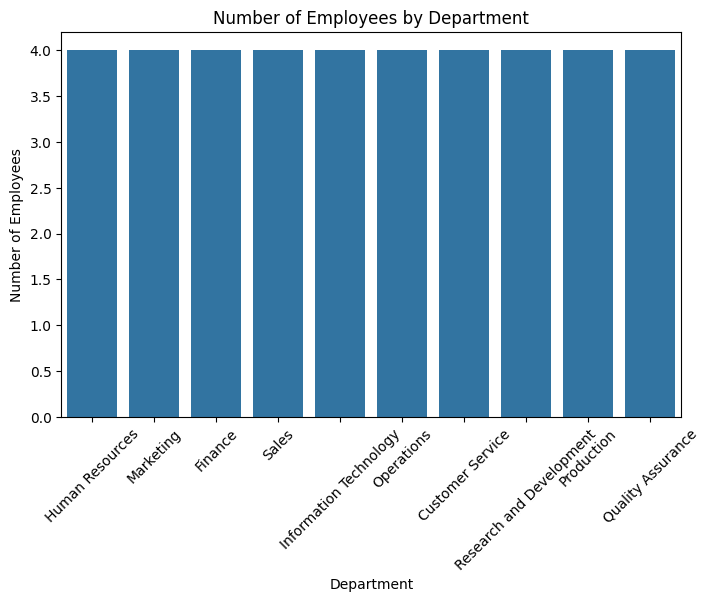

In [14]:
plt.figure(figsize=(8,5))

sns.countplot(data=data, x='Department')

plt.title('Number of Employees by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=45)

plt.show()

## histogram

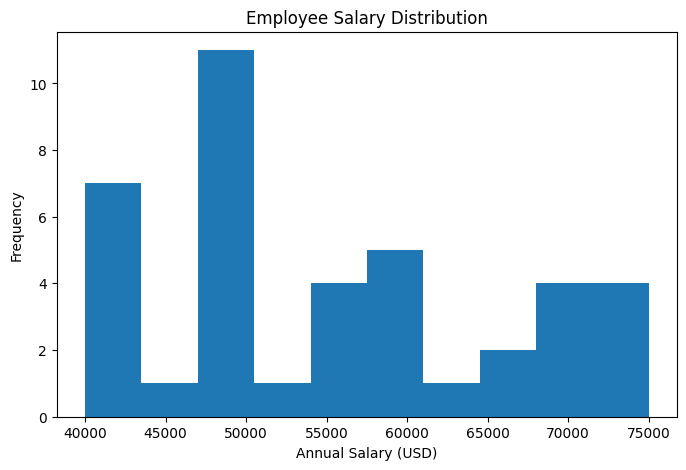

In [15]:
plt.figure(figsize=(8,5))

plt.hist(data['Annual Salary (USD)'], bins=10)

plt.title('Employee Salary Distribution')
plt.xlabel('Annual Salary (USD)')
plt.ylabel('Frequency')

plt.show()

## scatter plot

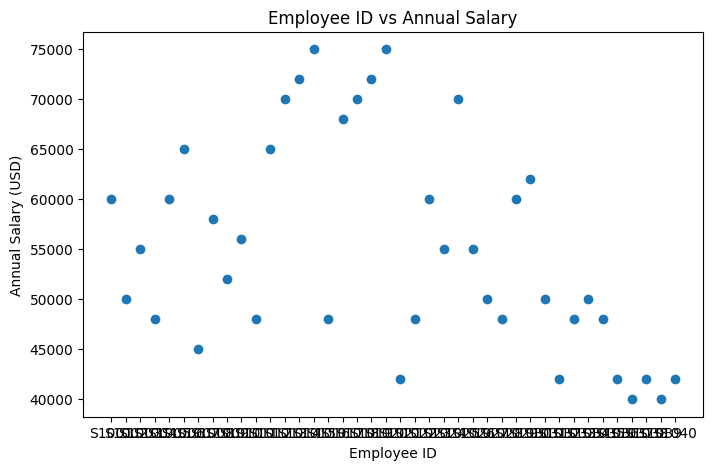

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(data['Employee ID'], data['Annual Salary (USD)'])

plt.title('Employee ID vs Annual Salary')
plt.xlabel('Employee ID')
plt.ylabel('Annual Salary (USD)')

plt.show()